# Historical CTA GTFS for routes 8 and 66: do archived feeds give us dated pattern stop lists?

TODO.md Phase 1, "Historical pattern geometry from GTFS, feasibility for routes 8 and 66". Exploratory, no spec.
The owner's Transitland Hobbyist/Academic access came through on 2026-11-22, so archived versions of feed
`f-dp3-cta` can now be downloaded (`docs/2026-11-21-gtfs-history-access.md` had only the version list).

Contains data from [Transitland](https://www.transit.land/terms): the feed versions read here were downloaded
from the Transitland Feed Archive (ADR-013). The current version also comes from CTA's own site and is
byte-identical to Transitland's latest.

The TODO item asks four things:

1. Does a mid-2024 version's route 8 stop list hold the stops Mansueto has before 2024-09-03 and today's patterns lack
   (9368: 15273, 16125, 15347, 5788, 5790; 9376: 15274, 15363, 5941, 15405)?
2. Does its distance along the shape for 9368's stops match, in feet, the `pdist` of the raw-CSV pings on 2024-07-16?
3. Which version first carries each route 8 and 66 detour, against the geometry changes dated from raw pings?
4. Does 6665 hold Wells & Chicago (`18803`) before 2025-11-24, and route 8's patterns the Blue Line stops `15341`
   and `18786`? Section 7 extends this to all 38 rows of `notebooks/routes_8_65_66_stop_validity.json`.

It changes no view, threshold or window. Not for riders (ADR-002).

In [1]:
%matplotlib inline

import datetime as dt
import hashlib
import json
import re
import sys
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from cta import bustracker, mansueto_raw
from cta.geo import straight_line_feet

_style = REPO_ROOT / "notebooks" / "cta_analysis.mplstyle"
if _style.is_file():
    plt.style.use(_style)
plt.rcParams["figure.dpi"] = 72  # keeps the committed notebook small
pd.set_option("display.max_rows", 200, "display.max_columns", 40, "display.width", 200, "display.max_colwidth", 90)

GTFS_DIR = REPO_ROOT / "data" / "gtfs"
FEED_DIR = GTFS_DIR / "feed_versions"  # <sha1>.zip and <sha1>.meta.json, one per version
RAW_DIR = REPO_ROOT / "data" / "mansueto_raw"  # as scripts/route_run_level.py caches the raw day CSVs
GETPATTERNS_FIXTURES = REPO_ROOT / "tests" / "fixtures" / "getpatterns"
PID_FILE = json.loads((REPO_ROOT / "notebooks" / "routes_8_65_66_pids.json").read_text())
VALIDITY = json.loads((REPO_ROOT / "notebooks" / "routes_8_65_66_stop_validity.json").read_text())

FEED = "f-dp3-cta"
TL_API = "https://transit.land/api/v2/rest"  # the session proxy adds the owner's key; never put it in code or .env
CTA_FEED_URL = "https://www.transitchicago.com/downloads/sch_data/google_transit.zip"
ROUTES = ["8", "65", "66"]
PIDS = ["9368", "9376", "6662", "6665"]  # the dominant route 8 and 66 patterns (EDA)
PID_LABEL = {"9368": "8 south (9368)", "9376": "8 north (9376)", "6662": "66 east (6662)", "6665": "66 west (6665)"}
PID_SHAPE_MODULUS = 100_000  # shape_id = 3-digit schedule prefix + 5-digit pid (section 2); "minus 68,200,000" holds for today's prefix only
MANSUETO_WINDOW = ("2024-09-03", "2026-07-27")  # Mansueto's stop lists switch on 2024-09-03 (EDA); its last service day
FT_PER_MILE = 5280

## 1. Feed versions: which ones, and the downloads

Transitland's metadata lists 184 versions. Each download counts against the plan's 500 a month, so each version is
fetched once, its SHA-1 checked against the version id, and kept under `data/gtfs/feed_versions/`. The download
endpoint answers 302 to a signed URL on `transitland.blob.core.windows.net` (allowed for the cloud environment on
2026-11-22). `fetch_version` asks for that URL without following it (one quota hit) and resumes the blob with Range
requests if the connection drops, as it did once at exactly 64 MiB.

The 22 versions cover every service day from 2024-07-08 to 2026-12-31 once each: the mid-2024 version for checks 1 and
2; every version fetched from 2025-06 to 2026-01, around the detours; and enough others to leave no day uncovered.
Today's version is taken from CTA's site; its SHA-1 equals Transitland's latest.

In [2]:
def feed_version_list(path: Path = GTFS_DIR / f"{FEED}_feed_versions.json") -> pd.DataFrame:
    """Transitland's metadata for every version of the feed (cached; metadata calls do not count as downloads)."""
    if not path.is_file():
        versions, after = [], None
        while True:
            url = f"{TL_API}/feeds/{FEED}/feed_versions?limit=100" + (f"&after={after}" if after else "")
            with urllib.request.urlopen(url, timeout=60) as r:
                page = json.load(r)
            versions += page["feed_versions"]
            after = (page.get("meta") or {}).get("after")
            if not after or not page["feed_versions"]:
                break
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(versions))
    v = pd.DataFrame(json.loads(path.read_text()))
    return v.assign(fetched=v["fetched_at"].str[:10]).sort_values("fetched_at").reset_index(drop=True)


class _NoRedirect(urllib.request.HTTPRedirectHandler):
    def redirect_request(self, *args, **kwargs):
        return None


def fetch_version(sha1: str, versions: pd.DataFrame) -> Path:
    """<sha1>.zip under FEED_DIR, downloaded once; refuses a file whose SHA-1 is not the version id."""
    out = FEED_DIR / f"{sha1}.zip"
    if out.is_file():
        return out
    FEED_DIR.mkdir(parents=True, exist_ok=True)
    try:  # one quota hit: the signed blob URL, not followed
        urllib.request.build_opener(_NoRedirect).open(f"{TL_API}/feed_versions/{sha1}/download", timeout=60)
        raise RuntimeError("expected a redirect to the feed archive")
    except urllib.error.HTTPError as exc:
        if exc.code not in (301, 302, 303, 307):
            raise  # 401: the key lacks archive access (playbook)
        blob = exc.headers["Location"]
    part = out.with_suffix(".part")
    for attempt in range(8):
        have = part.stat().st_size if part.exists() else 0
        req = urllib.request.Request(blob, headers={"Range": f"bytes={have}-"} if have else {})
        try:
            with urllib.request.urlopen(req, timeout=300) as r, part.open("ab") as f:
                if have and r.status != 206:
                    raise RuntimeError("the archive ignored the Range request")
                while chunk := r.read(1 << 20):
                    f.write(chunk)
            break
        except (ConnectionError, TimeoutError, urllib.error.URLError):
            continue
    digest = hashlib.sha1(part.read_bytes()).hexdigest()
    if digest != sha1:
        raise ValueError(f"downloaded {sha1} hashes to {digest}; left at {part}")
    part.rename(out)
    row = versions.set_index("sha1").loc[sha1]
    meta = {"sha1": sha1, "bytes": out.stat().st_size, "source": f"{TL_API}/feed_versions/{sha1}/download",
            "downloaded_at_utc": dt.datetime.now(dt.UTC).isoformat(timespec="seconds"), "fetched_at": row["fetched_at"],
            "earliest_calendar_date": row["earliest_calendar_date"], "latest_calendar_date": row["latest_calendar_date"], "feed": FEED}
    out.with_suffix(".meta.json").write_text(json.dumps(meta, indent=1))
    return out


VERSIONS = feed_version_list()
USED = {  # sha1 -> why it is read
    "1df549a1b0b7cfbe74b3546e84635515646e0136": "mid-2024: checks 1 and 2 (2024-07-16)",
    "d47ed8a7372487e24c13430982a01552d2070a98": "in force on 2024-09-03 (Mansueto's switch)",
    "172bf32d7bfa0d81e93585f44edd87282004f936": "after 2024-09-03",
    "f226158db362bf1039034aba6114420e92da3241": "coverage", "bb7910bb50ca31347df9420b6426cdd0517aab07": "coverage",
    "0395f1ec8d38f509880530e3f6035efa3e6709ac": "coverage", "1b4de7d5af5b9e71ea0169468ec10b3b1e3b1635": "coverage",
    "b01dc2d99d3c23362ccf7fc8f95263ca63ce2084": "around the 2025 detours", "78428dc43416f3a0be254cfcb2ea05ed2f65ebc9": "around the 2025 detours",
    "e3ebf32877de205c8bf930c77bfb366c19901d48": "around the 2025 detours", "ccdead314c38d04fde56933b09e6246e180037d4": "around the 2025 detours",
    "a664d63ce34554f88476278df6a5b66c873db9ee": "around the 2025 detours", "b99c500d69fc2661292a6dc3b23511e86765ff3b": "around the 2025 detours",
    "c07e68317b3e4452accfc9f09805727a88937458": "around the 2025 detours", "14d83314a4f56f375d6336a4bb7528df4487b055": "around the 2025 detours",
    "8e03d71e0152ea0c012488f6637b362d783a0412": "around the 2025 detours", "8e20b5d4fe7fe6f6a8da08a761f250947e4fccb9": "around the 2025 detours",
    "3fdb2739c597979bd0622b776496cb467d6bd3f4": "coverage", "81c806bbfb678eb3e3a8292a0a83f768bdb1009d": "coverage",
    "686b063b58e61693d948d8fcc8b12ee6a3313902": "coverage", "5e71fa8fce816d00887722920f70d53c438d5686": "coverage",
    "64cb6b84288a34196e3b7edf5ac5e79b5dfe1b7d": "today's (also CTA's own download): calibration",
}
for sha1 in USED:
    fetch_version(sha1, VERSIONS)
used = VERSIONS[VERSIONS["sha1"].isin(USED)][["fetched", "earliest_calendar_date", "latest_calendar_date", "sha1"]].copy()
used["MB"] = [round((FEED_DIR / f"{s}.zip").stat().st_size / 1e6, 1) for s in used["sha1"]]
used["why"] = used["sha1"].map(USED)
print(f"{len(VERSIONS)} versions listed; {len(used)} read, {used['MB'].sum():,.0f} MB")
display(used.reset_index(drop=True))

184 versions listed; 22 read, 1,627 MB


,fetched,earliest_calendar_date,latest_calendar_date,sha1,MB,why
0,2024-07-11,2024-07-08,2024-09-30,1df549a1b0b7cfbe74b3546e84635515646e0136,45.2,mid-2024: checks 1 and 2 (2024-07-16)
1,2024-08-22,2024-08-16,2024-10-31,d47ed8a7372487e24c13430982a01552d2070a98,91.4,in force on 2024-09-03 (Mansueto's switch)
2,2024-09-27,2024-09-24,2024-11-30,172bf32d7bfa0d81e93585f44edd87282004f936,67.4,after 2024-09-03
3,2024-10-17,2024-10-14,2024-12-31,f226158db362bf1039034aba6114420e92da3241,47.5,coverage
4,2025-03-12,2024-12-16,2025-03-31,bb7910bb50ca31347df9420b6426cdd0517aab07,93.4,coverage
5,2025-03-18,2025-03-13,2025-05-31,0395f1ec8d38f509880530e3f6035efa3e6709ac,95.1,coverage
6,2025-04-30,2025-04-28,2025-06-30,1b4de7d5af5b9e71ea0169468ec10b3b1e3b1635,67.6,coverage
7,2025-06-10,2025-06-09,2025-08-31,b01dc2d99d3c23362ccf7fc8f95263ca63ce2084,95.8,around the 2025 detours
8,2025-07-11,2025-07-08,2025-09-30,78428dc43416f3a0be254cfcb2ea05ed2f65ebc9,67.1,around the 2025 detours
9,2025-08-14,2025-08-12,2025-10-31,e3ebf32877de205c8bf930c77bfb366c19901d48,97.2,around the 2025 detours


## 2. Reading a version, and how shape ids encode the pid

One version is read for routes 8, 65 and 66 only. A trip's pattern is its ordered `(stop_id, shape_dist_traveled)`
list from `stop_times.txt`; every trip of a shape has the same one here (checked below). A shape's service days are
the calendar span of its trips' `service_id`s; no `calendar_dates.txt` addition falls outside it (checked).

`shape_id` is a three-digit schedule prefix followed by the five-digit pid: `66409368` in mid-2024, `67409368` from
2025-08-17, `68209368` today. The 2026-11-21 note's rule ("minus 68,200,000") holds for today's prefix only;
`shape_id % 100,000` holds in every version read. Most versions carry two schedule generations, each with its own
shape for the same pid and its own dates, so a geometry change shows up as the day a generation starts.

In [3]:
_STR = {c: pa.string() for c in ["route_id", "trip_id", "shape_id", "stop_id", "service_id", "block_id", "schd_trip_id",
                                 "direction_id", "start_date", "end_date", "date"]}


def _read(z: zipfile.ZipFile, name: str, cols: list[str] | None = None) -> pd.DataFrame:
    opts = pacsv.ConvertOptions(column_types=_STR, include_columns=cols)
    return pacsv.read_csv(z.open(name), convert_options=opts).to_pandas()


def read_version(sha1: str, routes=ROUTES) -> dict:
    """trips (with pid), shapes, stops, and one row per (shape_id) with its service span and pattern."""
    z = zipfile.ZipFile(FEED_DIR / f"{sha1}.zip")
    trips = _read(z, "trips.txt")
    trips = trips[trips["route_id"].isin(routes)].copy()
    trips["pid"] = (trips["shape_id"].astype(int) % PID_SHAPE_MODULUS).astype(str)
    st = _read(z, "stop_times.txt", ["trip_id", "stop_id", "stop_sequence", "shape_dist_traveled"])
    st = st[st["trip_id"].isin(set(trips["trip_id"]))].sort_values(["trip_id", "stop_sequence"])
    cal = _read(z, "calendar.txt").set_index("service_id")
    added = _read(z, "calendar_dates.txt").query("exception_type == 1")
    shapes = _read(z, "shapes.txt")
    shapes = shapes[shapes["shape_id"].isin(set(trips["shape_id"]))].sort_values(["shape_id", "shape_pt_sequence"])
    per_trip = st.groupby("trip_id").apply(
        lambda x: tuple(zip(x["stop_id"], x["shape_dist_traveled"].round().astype(int))), include_groups=False)
    rows = []
    for shape_id, g in trips.groupby("shape_id"):
        c = cal.loc[cal.index.intersection(g["service_id"].unique())]
        start, end = pd.Timestamp(c["start_date"].min()), pd.Timestamp(c["end_date"].max())
        extra = pd.to_datetime(added.loc[added["service_id"].isin(g["service_id"]), "date"])
        patterns = per_trip.loc[g["trip_id"]].value_counts()
        rows.append({"sha1": sha1, "route": g["route_id"].iloc[0], "pid": g["pid"].iloc[0], "shape_id": shape_id,
                     "direction": g["direction"].iloc[0], "trips": len(g), "start": start, "end": end,
                     "added_outside": int(((extra < start) | (extra > end)).sum()), "n_patterns": len(patterns),
                     "pattern": patterns.index[0]})
    return {"trips": trips, "shapes": shapes, "stops": _read(z, "stops.txt").set_index("stop_id"),
            "gens": pd.DataFrame(rows)}


V = {sha1: read_version(sha1) for sha1 in used["sha1"]}
GENS = pd.concat([v["gens"] for v in V.values()], ignore_index=True).merge(used[["sha1", "fetched"]], on="sha1")
GENS["sig"] = GENS["pattern"].map(lambda p: (tuple(s for s, _ in p), p[-1][1]))


def first_carrier(pid: str, day: pd.Timestamp, sig) -> str:
    """Fetch date of the earliest version read whose schedule has this pattern on this day."""
    g = GENS[(GENS["pid"] == pid) & (GENS["start"] <= day) & (GENS["end"] >= day)]
    return g.loc[g["sig"] == sig, "fetched"].min()


def stop_name(stop_id: str) -> str:
    for v in reversed(list(V.values())):  # newest version that has the id
        if stop_id in v["stops"].index:
            return v["stops"].loc[stop_id, "stop_name"]
    return "?"
print("shapes with more than one stop pattern:", int((GENS["n_patterns"] > 1).sum()),
      "| calendar_dates additions outside a shape's span:", int(GENS["added_outside"].sum()))
prefixes = GENS.assign(prefix=GENS["shape_id"].str[:3]).groupby("fetched")["prefix"].agg(lambda s: ", ".join(sorted(set(s))))
display(prefixes.to_frame("shape_id prefixes (routes 8, 65, 66)").T)
display(GENS[GENS["pid"] == "9368"][["fetched", "shape_id", "start", "end", "trips"]].reset_index(drop=True))

shapes with more than one stop pattern: 0 | calendar_dates additions outside a shape's span: 0


fetched,2024-07-11,2024-08-22,2024-09-27,2024-10-17,2025-03-12,2025-03-18,2025-04-30,2025-06-10,2025-07-11,2025-08-14,2025-09-09,2025-09-25,2025-10-13,2025-10-27,2025-11-20,2025-12-19,2026-01-08,2026-03-26,2026-05-30,2026-07-10,2026-09-16,2026-11-11
"shape_id prefixes (routes 8, 65, 66)",664,"666, 667","667, 668",668,"668, 669","669, 670","670, 671","671, 672","672, 673","673, 674",674,"674, 675","674, 675",675,"675, 676","676, 677",677,"677, 678","678, 679","679, 680","681, 682",682


,fetched,shape_id,start,end,trips
0,2024-07-11,66409368,2024-07-08,2024-09-30,271
1,2024-08-22,66609368,2024-08-16,2024-08-24,271
2,2024-08-22,66709368,2024-08-25,2024-10-31,271
3,2024-09-27,66709368,2024-09-24,2024-10-05,271
4,2024-09-27,66809368,2024-10-06,2024-11-30,271
5,2024-10-17,66809368,2024-10-14,2024-12-31,271
6,2025-03-12,66809368,2024-12-16,2024-12-21,271
7,2025-03-12,66909368,2024-12-22,2025-03-31,271
8,2025-03-18,66909368,2025-03-13,2025-03-22,271
9,2025-03-18,67009368,2025-03-23,2025-05-31,271


## 3. Calibration on today's feed: GTFS stop distances are Bus Tracker `pdist`

Today's version against the committed `getpatterns` fixtures (`tests/fixtures/getpatterns/`, today's geometry), stop
by stop. If `stop_times.shape_dist_traveled` equals `pdist`, an archived version is a dated `getpatterns`.

In [4]:
TODAY = "64cb6b84288a34196e3b7edf5ac5e79b5dfe1b7d"
rows = []
for pid in ["9368", "9376", "6662", "6665", "6656", "6657"]:
    gp = bustracker.stops_from_getpatterns(json.loads((GETPATTERNS_FIXTURES / f"getpatterns_{pid}.json").read_text()))
    g = V[TODAY]["gens"].query("pid == @pid").sort_values("trips").iloc[-1]
    gtfs = pd.DataFrame(g["pattern"], columns=["stpid", "gtfs_ft"])
    j = gp.merge(gtfs, on="stpid", how="left")
    diff = (j["gtfs_ft"] - j["pdist_ft"]).dropna()
    rows.append({"pid": pid, "getpatterns_stops": len(gp), "in_gtfs": int(j["gtfs_ft"].notna().sum()),
                 "missing_from_gtfs": ", ".join(j.loc[j["gtfs_ft"].isna(), "stpid"]),
                 "max_abs_diff_ft": float(diff.abs().max()), "last_stop_ft": int(gp["pdist_ft"].max())})
display(pd.DataFrame(rows))

,pid,getpatterns_stops,in_gtfs,missing_from_gtfs,max_abs_diff_ft,last_stop_ft
0,9368,107,106,18871,0.0,78822
1,9376,104,102,"5888, 18872",0.0,78248
2,6662,69,69,,0.0,50260
3,6665,70,70,,0.0,49442
4,6656,76,76,,0.0,55854
5,6657,76,76,,0.0,55777


## 4. `shapes.txt` distances are not reliable; `stop_times.txt` distances are

In versions that carry two schedule generations, some shapes' `shape_dist_traveled` in `shapes.txt` jumps by a
constant near the start (15,896 ft for 9376's), so the shape "ends" kilometres past its last stop. The same shape id,
with identical points, is normal in the next version, and `stop_times.txt` gives the same stop distances in both.
Route 8's short patterns (9343 to 9345) always end 3,688 to 3,756 ft past their last stop. Every distance below comes
from `stop_times.txt`; the one use of `shapes.txt` distances (section 6) is on shapes checked to be clean.

In [5]:
odd = []
for sha1, v in V.items():
    last_shape = v["shapes"].groupby("shape_id")["shape_dist_traveled"].max()
    last_stop = v["gens"].set_index("shape_id")["pattern"].map(lambda p: p[-1][1])
    gap = (last_shape - last_stop).dropna()
    for shape_id, ft in gap[gap.abs() > 100].items():
        odd.append({"fetched": used.set_index("sha1").loc[sha1, "fetched"], "shape_id": shape_id, "ft_past_last_stop": int(ft)})
odd = pd.DataFrame(odd)
odd["pid"] = (odd["shape_id"].astype(int) % PID_SHAPE_MODULUS).astype(str)
display(odd.groupby("pid")["ft_past_last_stop"].agg(["count", "min", "max"]))
print("dominant pids affected:", sorted(set(odd["pid"]) & set(PIDS)),
      "| versions:", ", ".join(sorted(odd.loc[odd["pid"] == "9376", "fetched"])))

,count,min,max
pid,,,
10949,12,13585,13607
10951,12,28641,28708
10954,12,39131,41293
8417,8,15498,15803
9343,38,3688,3756
9344,27,3688,3756
9345,38,3688,3756
9376,9,15864,15896


dominant pids affected: ['9376'] | versions: 2024-09-27, 2025-03-12, 2025-03-18, 2025-04-30, 2025-06-10, 2025-09-25, 2025-10-13, 2025-11-20, 2025-12-19


## 5. Check 1: the mid-2024 stop lists hold Mansueto's pre-2024-09-03 stops

In [6]:
MID_2024 = "1df549a1b0b7cfbe74b3546e84635515646e0136"
OLD_ONLY = {"9368": ["15273", "16125", "15347", "5788", "5790"], "9376": ["15274", "15363", "5941", "15405"]}
mid = V[MID_2024]
check1 = []
for pid, stops in OLD_ONLY.items():
    g = mid["gens"].query("pid == @pid").sort_values("trips").iloc[-1]
    ids = [s for s, _ in g["pattern"]]
    for s in stops:
        check1.append({"pid": pid, "shape_id": g["shape_id"], "stop_id": s, "name": mid["stops"].loc[s, "stop_name"],
                       "in_pattern": s in ids, "gtfs_ft": dict(g["pattern"]).get(s)})
check1 = pd.DataFrame(check1)
display(check1)
assert check1["in_pattern"].all()

,pid,shape_id,stop_id,name,in_pattern,gtfs_ft
0,9368,66409368,15273,Halsted & Division,True,17304
1,9368,66409368,16125,Halsted & North Branch,True,18970
2,9368,66409368,15347,Halsted & Chicago,True,19990
3,9368,66409368,5788,Halsted & Erie,True,20711
4,9368,66409368,5790,Halsted & Milwaukee/Grand (Blue Line),True,21587
5,9376,66409376,15274,Halsted & Milwaukee/Grand (Blue Line),True,53117
6,9376,66409376,15363,Halsted & Erie,True,53989
7,9376,66409376,5941,Halsted & Chicago,True,55077
8,9376,66409376,15405,Halsted & North Branch,True,55976


## 6. Check 2: distance along the mid-2024 shape against the `pdist` of raw pings

Each 2024-07-16 ping of the four pids (Mansueto raw day CSV) is projected onto its pid's mid-2024 GTFS shape (local
equirectangular frame, nearest segment), and its distance along the shape read from `shapes.txt` (clean for these
four shapes, asserted). `pdist − along` is the disagreement in feet. The same is done for 2026-09-15 against today's
version, whose stop distances equal `getpatterns` exactly (section 3): whatever the two days share is a property of
the pings, not of an old feed. Pings more than 200 ft off the shape (terminal layovers, one off-route fix) are left
out of the residuals. Per stop, the median residual of the pings within 1,000 ft along the shape.

In [7]:
FT_PER_DEG_LAT = 364_000.0  # 1 degree of latitude near Chicago; the projection only needs local accuracy
OFF_SHAPE_FT = 200  # 2026-11-21 stop-validity note: served stops sit within 214 ft of a ping; fixes farther off are layovers or off-route
NEAR_STOP_FT = 1_000  # about two stop spacings: enough pings at every stop at 300 s polling


def along_shape(shape: pd.DataFrame, lat: np.ndarray, lon: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Distance along the shape (its own units) of each point's projection, and the point's distance off it in feet."""
    kx = FT_PER_DEG_LAT * np.cos(np.radians(shape["shape_pt_lat"].mean()))
    x, y = shape["shape_pt_lon"].to_numpy() * kx, shape["shape_pt_lat"].to_numpy() * FT_PER_DEG_LAT
    d = shape["shape_dist_traveled"].to_numpy(float)
    ax, ay, vx, vy = x[:-1], y[:-1], np.diff(x), np.diff(y)
    seg2 = np.where(vx**2 + vy**2 == 0, 1e-9, vx**2 + vy**2)
    px, py = (lon * kx)[:, None], (lat * FT_PER_DEG_LAT)[:, None]
    t = np.clip(((px - ax) * vx + (py - ay) * vy) / seg2, 0, 1)
    off2 = (ax + t * vx - px) ** 2 + (ay + t * vy - py) ** 2
    k = off2.argmin(axis=1)
    r = np.arange(len(k))
    return d[:-1][k] + t[r, k] * np.diff(d)[k], np.sqrt(off2[r, k])


def ping_check(sha1: str, day: str) -> pd.DataFrame:
    path = mansueto_raw.fetch_day(day, RAW_DIR)
    pings = mansueto_raw.read_day(path, pids=PIDS)
    pings = pings[pings["data_date"] == day]  # each file also holds a few previous-day fixes
    v, out = V[sha1], []
    for pid in PIDS:
        g = v["gens"].query("pid == @pid").sort_values("trips").iloc[-1]
        shape = v["shapes"][v["shapes"]["shape_id"] == g["shape_id"]]
        assert abs(shape["shape_dist_traveled"].max() - g["pattern"][-1][1]) <= 100, "shapes.txt distances offset (section 4)"
        p = pings[pings["pid"] == pid]
        along, off = along_shape(shape, p["lat"].to_numpy(), p["lon"].to_numpy())
        on = off <= OFF_SHAPE_FT
        res = p["pdist"].to_numpy() - along
        per_stop = [np.median(res[on & (np.abs(along - ft) <= NEAR_STOP_FT)]) for _, ft in g["pattern"]]
        out.append({"day": day, "pid": pid, "shape_id": g["shape_id"], "pings": len(p), "off_shape": int((~on).sum()),
                    "off_ft_p95": round(float(np.percentile(off, 95))), "resid_p50": round(float(np.median(res[on]))),
                    "resid_p05": round(float(np.percentile(res[on], 5))), "resid_p95": round(float(np.percentile(res[on], 95))),
                    "abs_resid_p99": round(float(np.percentile(np.abs(res[on]), 99))), "stops": len(per_stop),
                    "stop_median_abs_max": round(float(np.nanmax(np.abs(per_stop)))),
                    "max_pdist_mi": round(p["pdist"].max() / FT_PER_MILE, 2), "last_stop_mi": round(g["pattern"][-1][1] / FT_PER_MILE, 2)})
    return pd.DataFrame(out)


check2 = pd.concat([ping_check(MID_2024, "2024-07-16"), ping_check(TODAY, "2026-09-15")], ignore_index=True)
display(check2)

,day,pid,shape_id,pings,off_shape,off_ft_p95,resid_p50,resid_p05,resid_p95,abs_resid_p99,stops,stop_median_abs_max,max_pdist_mi,last_stop_mi
0,2024-07-16,9368,66409368,1839,3,14,-46,-67,0,76,105,74,14.14,14.15
1,2024-07-16,9376,66409376,1829,9,172,-62,-88,-11,94,103,91,14.10,14.11
2,2024-07-16,6662,66406662,1830,0,1,-49,-69,-24,72,65,70,9.01,9.02
3,2024-07-16,6665,66406665,1849,1,1,-51,-70,0,82,66,68,8.88,8.89
4,2026-09-15,9368,68209368,2168,1,8,-47,-93,0,112,106,79,14.91,14.93
5,2026-09-15,9376,68209376,2113,6,163,-48,-67,3,71,102,67,14.81,14.82
6,2026-09-15,6662,68206662,2653,0,1,-51,-70,-8,82,69,70,9.51,9.52
7,2026-09-15,6665,68206665,2367,0,1,-44,-67,2,83,70,66,9.36,9.36


## 7. The pattern in force on each day, and check 3

Versions overlap. As in Mansueto's approach (ADR-009), each version is used from its first calendar day to the day
before the next version's first day, among the 22 read. Within a version, the generation whose calendar covers the
day gives the pattern. A *pattern change* is a change in the ordered stop list or in the last stop's distance; small
distance edits with the same stops (under 0.03 mi here) are listed but are not geometry changes.

In [8]:
spans = used.sort_values("fetched")[["sha1", "earliest_calendar_date"]].reset_index(drop=True)
spans["first"] = pd.to_datetime(spans["earliest_calendar_date"])
spans["last"] = spans["first"].shift(-1) - pd.Timedelta(days=1)
spans.loc[spans.index[-1], "last"] = pd.Timestamp("2026-12-31")
days = []
for s in spans.itertuples():
    for g in GENS[(GENS["sha1"] == s.sha1) & GENS["pid"].isin(PIDS)].itertuples():
        for day in pd.date_range(max(g.start, s.first), min(g.end, s.last)):
            days.append((g.pid, day, s.sha1, g.shape_id, g.pattern))
DAILY = pd.DataFrame(days, columns=["pid", "day", "sha1", "shape_id", "pattern"])
assert not DAILY.duplicated(["pid", "day"]).any()
for pid in PIDS:
    d = DAILY.loc[DAILY["pid"] == pid, "day"]
    assert len(pd.date_range(d.min(), d.max()).difference(d)) == 0, f"{pid}: uncovered days"
print("every day covered for each pid:", DAILY["day"].min().date(), "to", DAILY["day"].max().date())


def periods(pid: str) -> pd.DataFrame:
    x = DAILY[DAILY["pid"] == pid].sort_values("day").copy()
    x["sig"] = x["pattern"].map(lambda p: (tuple(s for s, _ in p), p[-1][1]))
    x["period"] = (x["sig"] != x["sig"].shift()).cumsum()
    per = x.groupby("period").agg(first=("day", "min"), last=("day", "max"), sig=("sig", "first"), sha1=("sha1", "first"),
                                  shape_ids=("shape_id", lambda s: ", ".join(dict.fromkeys(s))))
    per["stops"] = per["sig"].map(lambda s: len(s[0]))
    per["miles"] = per["sig"].map(lambda s: round(s[1] / FT_PER_MILE, 2))
    change, prev = [], None
    for sig in per["sig"]:
        if prev is None:
            change.append("")
        elif set(prev[0]) == set(sig[0]) and prev[0] == sig[0]:
            change.append(f"same stops, last stop {prev[1]:,} -> {sig[1]:,} ft")
        else:
            gone, new = sorted(set(prev[0]) - set(sig[0])), sorted(set(sig[0]) - set(prev[0]))
            change.append(f"-{len(gone)} +{len(new)}: -[{', '.join(gone)}] +[{', '.join(new)}]")
        prev = sig
    per["change"] = change
    per["first_in_version_fetched"] = [first_carrier(pid, p.first, p.sig) for p in per.itertuples()]
    return per.drop(columns=["sig", "sha1"]).reset_index(drop=True)


PERIODS = {pid: periods(pid) for pid in PIDS}
for pid in PIDS:
    print(PID_LABEL[pid])
    display(PERIODS[pid])

every day covered for each pid: 2024-07-08 to 2026-12-31
8 south (9368)


,first,last,shape_ids,stops,miles,change,first_in_version_fetched
0,2024-07-08,2024-12-21,"66409368, 66609368, 66709368, 66809368",105,14.15,,2024-07-11
1,2024-12-22,2025-03-22,66909368,105,14.18,"same stops, last stop 74,735 -> 74,853 ft",2025-03-12
2,2025-03-23,2025-05-03,67009368,105,14.18,"same stops, last stop 74,853 -> 74,848 ft",2025-03-18
3,2025-05-04,2025-08-16,"67109368, 67209368, 67309368",105,14.18,"same stops, last stop 74,848 -> 74,847 ft",2025-04-30
4,2025-08-17,2025-09-27,67409368,110,15.56,"-5 +10: -[15273, 15347, 16125, 5788, 5790] +[15672, 17184, 18156, 18786, 2028, 2032, 2...",2025-08-14
5,2025-09-28,2025-11-22,67509368,110,15.55,"same stops, last stop 82,134 -> 82,126 ft",2025-09-25
6,2025-11-23,2025-12-20,67609368,108,14.93,"-10 +8: -[15672, 17184, 18156, 18786, 2028, 2032, 2033, 769, 771, 772] +[15368, 15369,...",2025-11-20
7,2025-12-21,2026-03-28,67709368,108,14.93,-1 +1: -[5502] +[18786],2025-12-19
8,2026-03-29,2026-07-11,"67809368, 67909368",108,14.93,"same stops, last stop 78,811 -> 78,821 ft",2026-03-26
9,2026-07-12,2026-09-19,"68009368, 68109368",107,14.93,-1 +0: -[5812] +[],2026-07-10


8 north (9376)


,first,last,shape_ids,stops,miles,change,first_in_version_fetched
0,2024-07-08,2024-10-05,"66409376, 66609376, 66709376",103,14.11,,2024-07-11
1,2024-10-06,2024-12-21,66809376,103,14.11,"same stops, last stop 74,483 -> 74,482 ft",2024-09-27
2,2024-12-22,2025-05-03,"66909376, 67009376",103,14.09,"same stops, last stop 74,482 -> 74,395 ft",2025-03-12
3,2025-05-04,2025-08-16,"67109376, 67209376, 67309376",103,14.09,"same stops, last stop 74,395 -> 74,398 ft",2025-04-30
4,2025-08-17,2025-09-27,67409376,111,15.15,"-4 +12: -[15274, 15363, 15405, 5941] +[18402, 2042, 2043, 2045, 6712, 6713, 6714, 6715...",2025-08-14
5,2025-09-28,2025-11-22,67509376,111,15.15,"same stops, last stop 79,999 -> 80,015 ft",2025-09-25
6,2025-11-23,2026-03-28,"67609376, 67709376",105,14.81,"-12 +6: -[18402, 2042, 2043, 2045, 6712, 6713, 6714, 6715, 6716, 739, 741, 742] +[1534...",2025-11-20
7,2026-03-29,2026-07-11,"67809376, 67909376",105,14.82,"same stops, last stop 78,190 -> 78,248 ft",2026-03-26
8,2026-07-12,2026-09-19,"68009376, 68109376",104,14.82,-1 +0: -[5918] +[],2026-07-10
9,2026-09-20,2026-12-31,68209376,102,14.82,"-2 +0: -[17400, 5889] +[]",2026-09-16


66 east (6662)


,first,last,shape_ids,stops,miles,change,first_in_version_fetched
0,2024-07-08,2024-08-15,66406662,65,9.02,,2024-07-11
1,2024-08-16,2024-12-21,"66606662, 66706662, 66806662",65,9.02,"-2 +2: -[512, 513] +[18720, 18721]",2024-08-22
2,2024-12-22,2025-07-19,"66906662, 67006662, 67106662, 67206662",65,9.01,"same stops, last stop 47,639 -> 47,591 ft",2025-03-12
3,2025-07-20,2025-08-16,67306662,65,9.02,"same stops, last stop 47,591 -> 47,633 ft",2025-07-11
4,2025-08-17,2025-09-27,67406662,63,9.02,"-2 +0: -[565, 566] +[]",2025-08-14
5,2025-09-28,2025-11-22,67506662,70,9.51,"-3 +10: -[563, 567, 569] +[14762, 17834, 5500, 5502, 6712, 6713, 6714, 739, 741, 742]",2025-09-25
6,2025-11-23,2026-03-28,"67606662, 67706662",69,9.51,-1 +0: -[5502] +[],2025-11-20
7,2026-03-29,2026-12-31,"67806662, 67906662, 68006662, 68106662, 68206662",69,9.52,"same stops, last stop 50,231 -> 50,260 ft",2026-03-26


66 west (6665)


,first,last,shape_ids,stops,miles,change,first_in_version_fetched
0,2024-07-08,2024-08-15,66406665,66,8.89,,2024-07-11
1,2024-08-16,2024-10-05,"66606665, 66706665",66,8.90,"same stops, last stop 46,941 -> 46,984 ft",2024-08-22
2,2024-10-06,2024-12-21,66806665,66,8.90,"same stops, last stop 46,984 -> 46,983 ft",2024-09-27
3,2024-12-22,2025-03-22,66906665,66,8.90,"same stops, last stop 46,983 -> 46,987 ft",2025-03-12
4,2025-03-23,2025-05-03,67006665,66,8.90,"same stops, last stop 46,987 -> 46,993 ft",2025-03-18
5,2025-05-04,2025-08-16,"67106665, 67206665, 67306665",66,8.90,"same stops, last stop 46,993 -> 46,990 ft",2025-04-30
6,2025-08-17,2025-09-27,67406665,64,8.90,"-2 +0: -[612, 613] +[]",2025-08-14
7,2025-09-28,2025-11-22,67506665,69,9.46,"-3 +8: -[611, 615, 617] +[15341, 15672, 18792, 18793, 18794, 5525, 5527, 772]",2025-09-25
8,2025-11-23,2025-12-20,67606665,70,9.36,"-6 +7: -[17913, 18792, 18793, 606, 609, 620] +[18802, 18803, 5020, 6613, 6614, 769, 771]",2025-11-20
9,2025-12-21,2026-03-28,67706665,70,9.36,"same stops, last stop 49,420 -> 49,419 ft",2025-12-19


Check 3: the GTFS pattern changes against the geometry changes dated from raw pings
(`routes_8_65_66_pids.json` `geometry_changes`, the first day the longest `pdist` of the day moved). The
`first_in_version_fetched` column is the earliest version read whose schedule has the new pattern on its first day;
an earlier version covering that day still had the old one.

In [9]:
geo = pd.DataFrame(PID_FILE["geometry_changes"])
geo = geo[geo["pid"].isin(PIDS)].copy()
rows = []
for g in geo.itertuples():
    per = PERIODS[g.pid]
    big = per[(per["miles"] - per["miles"].shift()).abs() >= 0.05]  # geometry changes, not distance edits
    first_new = pd.Timestamp(g.first_day_new)
    k = (big["first"] - first_new).abs().idxmin()
    m = big.loc[k]
    rows.append({"pattern": PID_LABEL[g.pid], "pings_first_day_new": g.first_day_new, "pings_miles": f"{g.old_miles} -> {g.new_miles}",
                 "gtfs_first_day": m["first"].date().isoformat(), "gtfs_weekday": m["first"].day_name(),
                 "gtfs_miles": f"{per.loc[k - 1, 'miles']} -> {m['miles']}", "gtfs_minus_pings_days": (m["first"] - first_new).days,
                 "first_in_version_fetched": m["first_in_version_fetched"],
                 "published_days_ahead": (m["first"] - pd.Timestamp(m["first_in_version_fetched"])).days})
CHECK3 = pd.DataFrame(rows).sort_values(["pings_first_day_new", "pattern"]).reset_index(drop=True)
display(CHECK3)

,pattern,pings_first_day_new,pings_miles,gtfs_first_day,gtfs_weekday,gtfs_miles,gtfs_minus_pings_days,first_in_version_fetched,published_days_ahead
0,8 north (9376),2025-08-17,14.06 -> 15.14,2025-08-17,Sunday,14.09 -> 15.15,0,2025-08-14,3
1,8 south (9368),2025-08-17,14.15 -> 15.54,2025-08-17,Sunday,14.18 -> 15.56,0,2025-08-14,3
2,66 east (6662),2025-09-27,9.01 -> 9.5,2025-09-28,Sunday,9.02 -> 9.51,1,2025-09-25,3
3,66 west (6665),2025-09-28,8.89 -> 9.45,2025-09-28,Sunday,8.9 -> 9.46,0,2025-09-25,3
4,8 north (9376),2025-11-23,15.14 -> 14.81,2025-11-23,Sunday,15.15 -> 14.81,0,2025-11-20,3
5,66 west (6665),2025-11-24,9.45 -> 9.36,2025-11-23,Sunday,9.46 -> 9.36,-1,2025-11-20,3
6,8 south (9368),2025-11-25,15.54 -> 14.91,2025-11-23,Sunday,15.55 -> 14.93,-2,2025-11-20,3


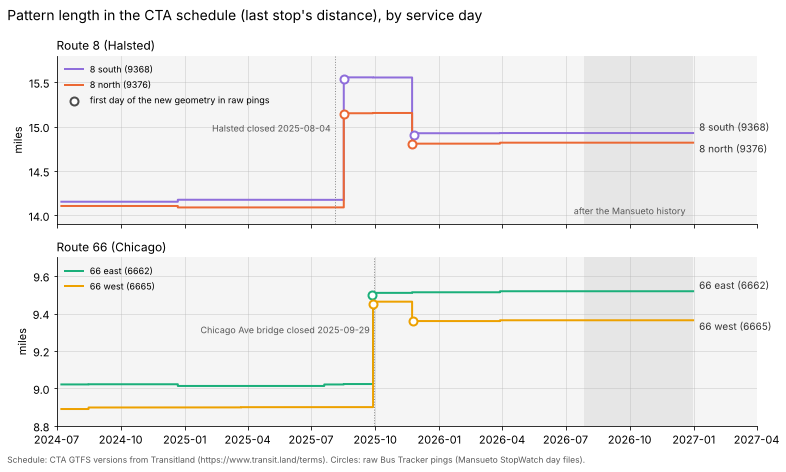

In [10]:
colors = dict(zip(PIDS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))  # fixed slot per pattern
PANELS = {"Route 8 (Halsted)": (["9368", "9376"], (13.9, 15.8), ("2025-08-04", "Halsted closed 2025-08-04")),
          "Route 66 (Chicago)": (["6662", "6665"], (8.8, 9.7), ("2025-09-29", "Chicago Ave bridge closed 2025-09-29"))}
NUDGE = {"9368": 6, "9376": -6, "6662": 6, "6665": -6}  # points: separates the two direct labels of a panel
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
for ax, (title, (pids, ylim, (closed, closed_text))) in zip(axes, PANELS.items()):
    for pid in pids:
        x = DAILY[DAILY["pid"] == pid].sort_values("day")
        miles = x["pattern"].map(lambda p: p[-1][1] / FT_PER_MILE)
        ax.step(x["day"], miles, where="post", color=colors[pid], lw=2, label=PID_LABEL[pid])
        ax.annotate(PID_LABEL[pid], (x["day"].iloc[-1], miles.iloc[-1]), xytext=(6, NUDGE[pid]), textcoords="offset points",
                    va="center", fontsize=10, color="0.2")
        g = geo[geo["pid"] == pid]
        ax.scatter(pd.to_datetime(g["first_day_new"]), g["new_miles"], s=64, facecolor="white", edgecolor=colors[pid], lw=2, zorder=3)
    ax.axvline(pd.Timestamp(closed), color="0.55", lw=1, ls=":")
    ax.annotate(closed_text, (pd.Timestamp(closed), 0.55), xycoords=("data", "axes fraction"), xytext=(-4, 0),
                textcoords="offset points", ha="right", fontsize=9, color="0.35")
    ax.axvspan(pd.Timestamp(MANSUETO_WINDOW[1]), pd.Timestamp("2026-12-31"), color="0.85", alpha=0.5, lw=0)
    ax.set_ylim(*ylim)
    ax.set_ylabel("miles")
    ax.set_title(title, loc="left", fontsize=12)
axes[0].scatter([], [], s=64, facecolor="white", edgecolor="0.3", lw=2, label="first day of the new geometry in raw pings")
axes[0].legend(loc="upper left", fontsize=9, frameon=False)
axes[1].legend(loc="upper left", fontsize=9, frameon=False)
axes[0].annotate("after the Mansueto history", (pd.Timestamp("2026-10-01"), 0.06), xycoords=("data", "axes fraction"),
                 ha="center", fontsize=9, color="0.35")
axes[1].set_xlim(pd.Timestamp("2024-07-01"), pd.Timestamp("2027-04-01"))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.suptitle("Pattern length in the CTA schedule (last stop's distance), by service day", x=0.01, ha="left", fontsize=14)
fig.text(0.01, -0.01, "Schedule: CTA GTFS versions from Transitland (https://www.transit.land/terms). Circles: raw Bus Tracker pings "
         "(Mansueto StopWatch day files).", fontsize=8.5, color="0.35")
fig.tight_layout()
plt.show()

## 8. Check 4, extended to every row of the committed stop-validity windows

For each of the 38 rows of `routes_8_65_66_stop_validity.json`: the days in the Mansueto window (2024-09-03 to
2026-07-27) on which the stop id is in its pid's GTFS pattern, against the committed `valid_from` (none means served
for the whole window). Where they differ, the period before the GTFS start is read for the intersection: a pattern
stop with the same street names (e.g. `5790` "Halsted & Milwaukee/Grand (Blue Line)" for `18786`) means the corner
was served under another id; none means the pattern had no stop at that corner. Only days from the committed window's start are read.

In [11]:
W0, W1 = map(pd.Timestamp, MANSUETO_WINDOW)
LATEST_STOPS = V[TODAY]["stops"]
SAME_CHANGE_DAYS = 3  # pick dates are Sundays; ping-dated changes fall within two days of them (section 7)


def streets(name: str) -> frozenset:
    return frozenset(w.strip().lower() for w in re.split(r"[&/]", re.sub(r"\(.*?\)", "", name)) if w.strip())


def presence(pid: str, stop: str) -> list[tuple[str, str]]:
    x = DAILY[(DAILY["pid"] == pid) & DAILY["day"].between(W0, W1)].sort_values("day")
    on = x["pattern"].map(lambda p: stop in {s for s, _ in p}).to_numpy()
    days, runs, i = x["day"].dt.date.astype(str).to_numpy(), [], 0
    while i < len(on):
        if on[i]:
            j = i
            while j + 1 < len(on) and on[j + 1]:
                j += 1
            runs.append((days[i], days[j]))
            i = j + 1
        else:
            i += 1
    return runs


def corner_when_absent(pid: str, stop: str, since: str = MANSUETO_WINDOW[0]) -> list[str]:
    """Per period without the id, from `since` (the committed window's start): the same-corner pattern stop, or the
    nearest stop when the corner has none."""
    c = LATEST_STOPS.loc[stop]
    x = DAILY[(DAILY["pid"] == pid) & DAILY["day"].between(pd.Timestamp(since), W1)].sort_values("day").copy()
    x["ids"] = x["pattern"].map(lambda p: tuple(s for s, _ in p))
    x["period"] = (x["ids"] != x["ids"].shift()).cumsum()
    out = []
    for _, g in x.groupby("period"):
        ids, st = g["ids"].iloc[0], V[g["sha1"].iloc[0]]["stops"]
        if stop in ids:
            continue
        near = sorted((straight_line_feet(c.stop_lat, c.stop_lon, st.loc[s, "stop_lat"], st.loc[s, "stop_lon"]), s) for s in ids)
        same = [(f, s) for f, s in near if streets(st.loc[s, "stop_name"]) == streets(c.stop_name)]
        f, s = (same or near)[0]
        kind = "same corner as" if same else "NO STOP at this corner; nearest"
        out.append(f"{g['day'].min().date()} to {g['day'].max().date()}: {kind} {s} {st.loc[s, 'stop_name']} ({f:,.0f} ft)")
    return out


rows = []
for r in VALIDITY["rows"]:
    runs = presence(r["from_pid"], r["stop_id"])
    committed = r["valid_from"] or MANSUETO_WINDOW[0]
    gtfs_from = runs[-1][0] if runs and runs[-1][1] == MANSUETO_WINDOW[1] else None
    gap = (pd.Timestamp(gtfs_from) - pd.Timestamp(committed)).days if gtfs_from else None
    if len(runs) == 1 and gap == 0:
        verdict = "agrees"
    elif len(runs) == 1 and abs(gap) <= SAME_CHANGE_DAYS and r["valid_from"]:
        verdict = f"same change, GTFS {gap:+d} d"
    else:
        notes = corner_when_absent(r["from_pid"], r["stop_id"], committed)
        verdict = "corner had no stop" if any("NO STOP" in n for n in notes) else "id changed at the same corner"
    rows.append({"pid": r["from_pid"], "stop_id": r["stop_id"], "name": r["stop_name"], "committed_valid_from": r["valid_from"],
                 "gtfs_in_pattern": "; ".join(f"{a} to {b}" for a, b in runs), "verdict": verdict})
CHECK4 = pd.DataFrame(rows)
display(CHECK4)
display(CHECK4["verdict"].value_counts().to_frame("rows"))

,pid,stop_id,name,committed_valid_from,gtfs_in_pattern,verdict
0,6662,18720,Chicago & Menard,NaN,2024-09-03 to 2026-07-27,agrees
1,6662,18721,Chicago & Waller,NaN,2024-09-03 to 2026-07-27,agrees
2,6662,17834,Milwaukee & Carpenter,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"
3,6662,5500,Milwaukee & Erie,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"
4,6662,739,Grand & Union,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"
5,6662,741,530 W Grand,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"
6,6662,742,Grand & Kingsbury,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"
7,6662,14762,Orleans & Grand,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"
8,6662,6712,Orleans & Erie,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"
9,6662,6713,Orleans & Huron,2025-09-27,2025-09-28 to 2026-07-27,"same change, GTFS +1 d"


,rows
verdict,
agrees,12
"same change, GTFS +1 d",8
"same change, GTFS -2 d",6
id changed at the same corner,5
"same change, GTFS -1 d",4
corner had no stop,3


The rows that differ by more than a few days, period by period:

In [12]:
for r in CHECK4[CHECK4["verdict"].isin(["corner had no stop", "id changed at the same corner"])].itertuples():
    committed = None if pd.isna(r.committed_valid_from) else r.committed_valid_from  # pandas 3 stores None as NaN (playbook)
    print(f"{r.pid} {r.stop_id} {r.name} (committed valid_from: {committed or 'none'}; GTFS: {r.gtfs_in_pattern})")
    for line in corner_when_absent(r.pid, r.stop_id, committed or MANSUETO_WINDOW[0]):
        print("   ", line)

6662 6714 Orleans & Chicago (committed valid_from: none; GTFS: 2025-09-28 to 2026-07-27)
    2024-09-03 to 2025-08-16: NO STOP at this corner; nearest 572 Chicago & Franklin (Brown line) (317 ft)
    2025-08-17 to 2025-09-27: NO STOP at this corner; nearest 572 Chicago & Franklin (Brown line) (317 ft)
6665 18803 Wells & Chicago (committed valid_from: none; GTFS: 2025-11-23 to 2026-07-27)
    2024-09-03 to 2025-08-16: NO STOP at this corner; nearest 606 Chicago & Franklin (Brown line) (385 ft)
    2025-08-17 to 2025-09-27: NO STOP at this corner; nearest 606 Chicago & Franklin (Brown line) (385 ft)
    2025-09-28 to 2025-11-22: NO STOP at this corner; nearest 606 Chicago & Franklin (Brown line) (383 ft)
6665 771 Grand & Kingsbury (committed valid_from: 2025-09-28; GTFS: 2025-11-23 to 2026-07-27)
    2025-09-28 to 2025-11-22: same corner as 18793 Kingsbury & Grand (86 ft)
6665 18794 Chicago & Milwaukee (Blue Line) (committed valid_from: none; GTFS: 2025-09-28 to 2026-07-27)
    2024-09-0

## 9. Side checks

- Mansueto's stop lists switch on 2024-09-03. Does the schedule change then?
- Stops of today's `getpatterns` patterns, outside the 38 candidates, that GTFS does not hold for the whole Mansueto
  window; and stops GTFS holds in the window that today's `getpatterns` lacks (their Mansueto arrivals are dropped as
  `stop_not_in_pattern`).

In [13]:
for pid in PIDS:
    per = PERIODS[pid]
    near = per[(per["first"] >= "2024-08-01") & (per["first"] <= "2024-10-31")]
    print(PID_LABEL[pid], "| pattern changes starting 2024-08-01 to 2024-10-31:",
          "; ".join(f"{p.first.date()} {p.change}" for p in near.itertuples()) or "none")

cand = {(r["from_pid"], r["stop_id"]) for r in VALIDITY["rows"]}
extra = []
for pid in PIDS:
    gp = bustracker.stops_from_getpatterns(json.loads((GETPATTERNS_FIXTURES / f"getpatterns_{pid}.json").read_text()))
    for s, name in zip(gp["stpid"], gp["stpnm"]):
        runs = presence(pid, s)
        if (pid, s) not in cand and runs != [MANSUETO_WINDOW]:
            extra.append({"pid": pid, "stop_id": s, "name": name, "side": "in getpatterns today", "gtfs_in_pattern": runs or "never"})
    in_window = set().union(*DAILY[(DAILY["pid"] == pid) & DAILY["day"].between(W0, W1)]["pattern"].map(lambda p: {s for s, _ in p}))
    for s in sorted(in_window - set(gp["stpid"])):
        runs = presence(pid, s)
        name = stop_name(s)
        extra.append({"pid": pid, "stop_id": s, "name": name, "side": "only in GTFS", "gtfs_in_pattern": runs})
display(pd.DataFrame(extra))

8 south (9368) | pattern changes starting 2024-08-01 to 2024-10-31: none
8 north (9376) | pattern changes starting 2024-08-01 to 2024-10-31: 2024-10-06 same stops, last stop 74,483 -> 74,482 ft
66 east (6662) | pattern changes starting 2024-08-01 to 2024-10-31: 2024-08-16 -2 +2: -[512, 513] +[18720, 18721]
66 west (6665) | pattern changes starting 2024-08-01 to 2024-10-31: 2024-08-16 same stops, last stop 46,941 -> 46,984 ft; 2024-10-06 same stops, last stop 46,984 -> 46,983 ft


,pid,stop_id,name,side,gtfs_in_pattern
0,9368,18871,Halsted & 56th Street,in getpatterns today,never
1,9368,15273,Halsted & Division,only in GTFS,"[(2024-09-03, 2025-08-16)]"
2,9368,15347,Halsted & Chicago,only in GTFS,"[(2024-09-03, 2025-08-16)]"
3,9368,15672,Grand & Desplaines,only in GTFS,"[(2025-08-17, 2025-11-22)]"
4,9368,16125,Halsted & North Branch,only in GTFS,"[(2024-09-03, 2025-08-16)]"
5,9368,17184,Division & Halsted,only in GTFS,"[(2025-08-17, 2025-11-22)]"
6,9368,18156,Division & Clybourn,only in GTFS,"[(2025-08-17, 2025-11-22)]"
7,9368,2028,Division & Larrabee,only in GTFS,"[(2025-08-17, 2025-11-22)]"
8,9368,2032,311 W Division,only in GTFS,"[(2025-08-17, 2025-11-22)]"
9,9368,2033,Division & Wells,only in GTFS,"[(2025-08-17, 2025-11-22)]"


## Findings

Measured 2026-11-22 from 22 versions of CTA's GTFS feed `f-dp3-cta`, covering every service day from 2024-07-08 to
2026-12-31 (21 from the Transitland Feed Archive, 25 download requests against the plan's 500 a month; today's from
CTA's site, byte-identical to Transitland's latest), the committed `getpatterns` fixtures and the Mansueto raw day
files of 2024-07-16 and 2026-09-15. Contains data from [Transitland](https://www.transit.land/terms). Recorded in
`docs/2026-11-22-gtfs-history-routes-8-66.md`.

1. **An archived GTFS version is a dated `getpatterns`.** Today, `stop_times.shape_dist_traveled` equals `getpatterns`
   `pdist` at every shared stop of 9368, 9376, 6662, 6665, 6656 and 6657 (0 ft difference). Stop ids are `stpid`s,
   and the pid is `shape_id % 100,000` in every version: the shape id's three-digit prefix changes with each schedule
   generation (664 in mid-2024, 674 from 2025-08-17, 682 today), so "minus 68,200,000" holds for today's prefix only.
2. **Check 1 holds.** The mid-2024 version (fetched 2024-07-11) has all five old stops in 9368 (15273, 16125, 15347,
   5788, 5790) and all four in 9376 (15274, 15363, 5941, 15405), with their distances.
3. **Check 2 holds.** On 2024-07-16, 1,820 to 1,848 pings per pid sit on the mid-2024 shapes (95th percentile 1 to
   172 ft off, the high end at a terminal layover). `pdist` minus the distance along the shape has a median of −46 to
   −62 ft and 99% within 72 to 94 ft; per stop, the median is within 68 to 91 ft. Today's feed against 2026-09-15 gives
   the same (median −44 to −51 ft, 99% within 71 to 112 ft), so the ~50 ft belongs to the pings (the reported `pdist`
   trails the reported position), not to the old feed. 9368's mid-2024 pattern is 14.15 mi; the longest ping that day
   14.14 mi.
4. **Check 3: the schedule and Bus Tracker changed geometry together, on Sunday schedule starts, each in a version
   fetched three days ahead.** GTFS changed 8 north and south on 2025-08-17, 66 east and west on 2025-09-28, and 8 north
   and south and 66 west on 2025-11-23 (versions fetched 2025-08-14, 2025-09-25 and 2025-11-20). The pings date four of
   the seven changes to the same day; 6662's a day earlier (2025-09-27), 6665's a day later (2025-11-24) and 9368's two
   days later (2025-11-25). Route 8's buses moved on 2025-08-04 by travel time, so both trailed that detour by 13 days;
   route 66's came a day before the bridge closed (2025-09-29).
5. **Check 4.** Wells & Chicago (`18803`) is in 6665's pattern only from 2025-11-23, and before that no 6665 stop stood
   at the corner (nearest Chicago & Franklin, 385 ft). `15341` is in 9376's pattern only from 2025-11-23: before
   2025-08-17 the corner was served as `15274` (122 ft), from 2025-08-17 to 2025-11-22 by no stop (nearest 440 ft).
   `18786` is in 9368's pattern from 2025-08-17, the corner served as `5790` (228 ft) before; it drops out from
   2025-11-23 to 2025-12-20, when `5502` (189 ft) stands in.
6. **Across the 38 committed windows**: 12 agree; 18 are the same change dated one or two days apart (6662's eight
   stops, GTFS +1 day; 6665's four Wells and Grand & Franklin stops, −1; 9368's six Division and Milwaukee stops, −2);
   5 are id changes at a corner the pattern served under another id (`18786`, `5782`, `18794`, `18802`, and `771` from
   2025-09-28 to 2025-11-22, served as `18793`, 86 ft); 3 have a period when the corner had no stop: Orleans & Chicago
   (6662, `6714`) before 2025-09-28 (nearest 317 ft), Wells & Chicago before 2025-11-23, and `15341` on 9376 from
   2025-08-17 to 2025-11-22. The first two are corner stops of the kind the ping method cannot see (playbook). Nothing
   here changes a window: which rows become reviewed overrides, and whether a stop served under another id counts as
   served, is the owner's call (TODO.md).
7. **The schedule did not change on 2024-09-03**, the day Mansueto's stop lists switched. The Chicago & Menard and
   Waller id swap (`512`, `513` → `18720`, `18721`) was in the schedule by 2024-08-16 (not in the version fetched
   2024-07-11), and the detour stops arrived only in 2025. Route 66 also lost its Chicago & Halsted stops (6662 `565`,
   `566`; 6665 `612`, `613`) on 2025-08-17, with route 8's detour, six weeks before its own.
8. **`shapes.txt` distances are unreliable; `stop_times.txt` distances are not.** In 9 of the 22 versions, 9376's
   shape runs 15,864 to 15,896 ft past its last stop (a constant jump near the start; the same shape id is normal in
   the next version), and route 8's short patterns always end about 3,700 ft past theirs. Read stop distances from
   `stop_times.txt`.
9. **Today's GTFS and `getpatterns` disagree at Halsted & 56th and 57th.** GTFS held `5838` (9368) and `5889`,
   `17400` (9376) to 2026-09-19 and has no stop there since; `getpatterns` serves `18871`, `18872` and `5888`, which no
   version read holds. GTFS also dropped 2300 S Halsted (`5812`, `5918`) on 2026-07-12. Those five ids are absent from
   today's `getpatterns`, so any Mansueto arrivals under them are dropped as `stop_not_in_pattern`.
10. **Both conditions of the TODO item hold**, so the follow-ups it names each get a spec: dated pattern stop tables
    from GTFS; the stop-validity review (now with GTFS evidence for every row); keeping the pre-2024-09-03 arrivals;
    and imputing 2024-09-03 to 2025-08-03 from the raw CSVs.